[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/event_kernels_tutorial.ipynb)

# Event-restricted kernels

`timecorr` estimates the correlations at timepoint `t` from a kernel-weighted window of timepoints around `t`. With the `events` option, that window is confined to the current **event**: a block of consecutive timepoints. Timepoints in other blocks get zero weight, even when they are close to `t`. The blocks come either from boundary indices that you pass, or from segmenting a separate timeseries (for example features of a stimulus over time) with `tc.segment`.

This notebook uses synthetic data only:

1. what the restriction does to a kernel;
2. passing boundaries to `timecorr`;
3. segmenting synthetic "stimulus embeddings" with `tc.segment` (ordered events and recurring states), and using the result on synthetic brain data, with the recovery of the true correlations compared against the unrestricted kernel and against wrong boundaries;
4. per-subject events, and what they mean for cross-subject correlations (ISFC);
5. different events at each order in `tc.features`.

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere).
# It installs version 0.3.0 or later from PyPI; if that release is not on PyPI yet,
# it installs from GitHub instead. Colab may ask you to restart the runtime after
# installing; if it does, restart it and run all cells again.
import sys
if "google.colab" in sys.modules:
    !pip install -q "timecorr[segment]>=0.3.0" 2>/dev/null || pip install -q "timecorr[segment] @ git+https://github.com/ContextLab/timecorr.git@master"

In [2]:
import warnings
from importlib.metadata import PackageNotFoundError, version

import numpy as np
import matplotlib.pyplot as plt

import timecorr as tc
from timecorr.events import mask_kernel

%matplotlib inline
plt.rcParams['figure.dpi'] = 72
blue, orange, gray, green = '#2a78d6', '#eb6834', '0.55', '#2e9e5b'

print('timecorr ', tc.__version__)
print('numpy    ', np.__version__)
try:
    print('hmmlearn ', version('hmmlearn'))
except PackageNotFoundError:
    print('hmmlearn ', 'not installed (tc.segment installs it on demand)')

timecorr  0.3.0
numpy     2.4.6
hmmlearn  0.3.3


## 1. What the restriction does to a kernel

Row `t` of the `T x T` kernel matrix holds the weights used at timepoint `t`. Given a boundary set (the timepoints at which new blocks start), `timecorr` sets `weights[t, u] = 0` whenever `t` and `u` lie in different blocks. This happens after `include_timepoints`, `include_zero` and `exclude_timepoints` have been applied. The estimator normalizes each row, so the remaining weights need no rescaling. `timecorr.events.mask_kernel` applies the same step to any kernel matrix, which makes it easy to look at.

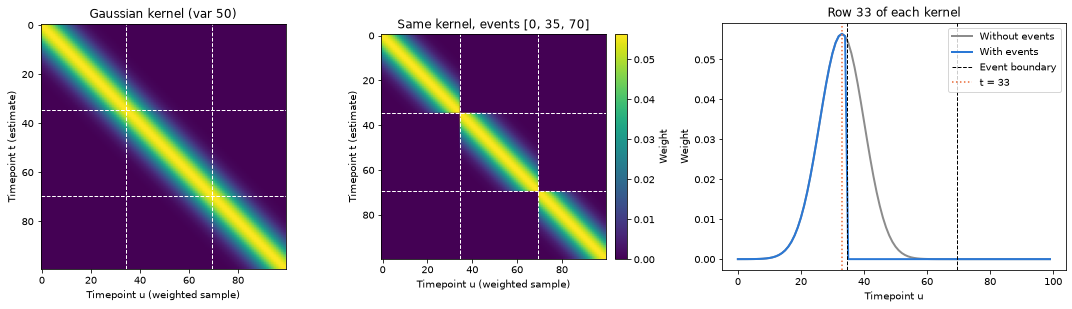

In [3]:
T1 = 100
bounds1 = [0, 35, 70]                      # blocks 0-34, 35-69, 70-99
full = tc.gaussian_weights(T1, {'var': 50})
masked = mask_kernel(full, bounds1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={'width_ratios': [1, 1, 1.4]})
for ax, w, title in zip(axes[:2], (full, masked), ('Gaussian kernel (var 50)', 'Same kernel, events [0, 35, 70]')):
    im = ax.imshow(w, cmap='viridis', origin='upper')
    for b in bounds1[1:]:
        ax.axvline(b - 0.5, color='w', ls='--', lw=1)
        ax.axhline(b - 0.5, color='w', ls='--', lw=1)
    ax.set_title(title)
    ax.set_xlabel('Timepoint u (weighted sample)')
    ax.set_ylabel('Timepoint t (estimate)')
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04, label='Weight')

t0 = 33
ax = axes[2]
ax.plot(full[t0], color=gray, lw=2, label='Without events')
ax.plot(masked[t0], color=blue, lw=2, label='With events')
for i, b in enumerate(bounds1[1:]):
    ax.axvline(b - 0.5, color='k', ls='--', lw=1, label='Event boundary' if i == 0 else None)
ax.axvline(t0, color=orange, ls=':', lw=1.5, label=f't = {t0}')
ax.set_title(f'Row {t0} of each kernel')
ax.set_xlabel('Timepoint u')
ax.set_ylabel('Weight')
ax.legend(loc='upper right', fontsize=10)
fig.tight_layout()

Near a boundary the unrestricted kernel (gray) gives substantial weight to timepoints on both sides of it. The restricted kernel (blue) keeps only the timepoints of `t`'s own block, so its estimate at `t = 33` uses timepoints 0 to 34 only.

## 2. Passing boundaries

`events` takes a boundary set: a list (or tuple, 1-D integer array, or pandas/polars Series) of the timepoints at which new blocks start. Index 0 is implied, the boundaries are sorted and de-duplicated, and an empty list means a single block (no restriction). The kernel then gives no weight to timepoints outside the current block, so the output for a block equals `timecorr` run on that block's rows alone with the matching part of the kernel:

In [4]:
rng = np.random.default_rng(0)
data = rng.standard_normal((T1, 5))
params = {'var': 50}

corrs = tc.timecorr(data, weights_params=params, events=[35, 70])
print('output shape:', corrs.shape)

alone = tc.timecorr(data[35:70], weights_function=lambda T, p: full[35:70, 35:70])
print('block 35-69 equals timecorr on its rows alone:', np.allclose(corrs[35:70], alone))

unrestricted = tc.timecorr(data, weights_params=params)
print('events=[] equals no events:', np.array_equal(tc.timecorr(data, weights_params=params, events=[]), unrestricted))
print('largest change from restricting the kernel:', np.abs(corrs - unrestricted).max().round(3))

output shape: (100, 15)
block 35-69 equals timecorr on its rows alone: True
events=[] equals no events: True
largest change from restricting the kernel: 0.545


The same restricted kernel is used by the smoothing path (`cfun=None`). A block shorter than 3 timepoints leaves its rows with fewer than 3 non-zero weights, so its correlations are undefined: they are set to 0 and `timecorr` warns once per call. If the events leave *every* row with fewer than 3 non-zero weights, `timecorr` raises `ValueError`.

In [5]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    tc.timecorr(data, weights_params=params, events=[35, 70, 98])   # last block: timepoints 98-99
for w in caught:
    print(w.message)

2 of 100 timepoints have fewer than 3 non-zero kernel weights; their correlations are undefined and set to 0.


## 3. Segmenting a stimulus timeseries, and using the events on brain data

Event boundaries often come from a separate timeseries that describes what happened at each moment, for example text embeddings of a story, or behavioral annotations. `tc.segment(features, n=None, kind='ordered', max_events=50, random_state=None, return_states=False)` fits a Gaussian hidden Markov model (from `hmmlearn`) to such a timepoints-by-features array and returns the block starts.

`hmmlearn` is not a required dependency of timecorr; it is in the `segment` extra (`pip install "timecorr[segment]"`). The first time `tc.segment` needs it and it is missing, timecorr installs it into the running interpreter with `python -m pip install hmmlearn` and prints a one-line notice. Setting the environment variable `TIMECORR_AUTO_INSTALL=0` (or `false`, or `no`) before calling `tc.segment` turns this off; `tc.segment` then raises `ImportError` with the command above. Passing boundaries never needs `hmmlearn`.

### Synthetic stimulus and brain data

The generator below draws events of 40 to 120 timepoints over `T = 600` timepoints. Within each event:

- the **stimulus embedding** (20 features) is the event's own random mean pattern plus independent noise of the same size;
- the **brain data** (10 features) are drawn from the event's own random correlation matrix, so the true correlation matrix at timepoint `t` is that of `t`'s event.

The **wrong boundaries** are the same number of boundaries placed at random; they are the control for the comparison below.

In [6]:
T, K, E = 600, 10, 20
iu = np.triu_indices(K, 1)


def make_data(seed):
    """Stimulus embedding, brain data, true correlations, true and wrong boundaries."""
    rng = np.random.default_rng(seed)
    bounds = [0]
    while bounds[-1] < T:
        bounds.append(bounds[-1] + int(rng.integers(40, 121)))
    bounds = [b for b in bounds if b < T]
    ends = bounds[1:] + [T]
    embedding = np.zeros((T, E))
    for a, b in zip(bounds, ends):
        embedding[a:b] = rng.standard_normal(E) + rng.standard_normal((b - a, E))
    brain, truth = np.zeros((T, K)), np.zeros((T, len(iu[0])))
    for a, b in zip(bounds, ends):
        A = rng.standard_normal((K, 3))
        C = A @ A.T + np.eye(K)
        d = np.sqrt(np.diag(C))
        C = C / np.outer(d, d)
        brain[a:b] = rng.multivariate_normal(np.zeros(K), C, size=b - a)
        truth[a:b] = C[iu]
    wrong = [0] + sorted(rng.choice(np.arange(20, T - 20), len(bounds) - 1, replace=False).tolist())
    return embedding, brain, truth, np.array(bounds), np.array(wrong)


embedding, brain, truth, true_bounds, wrong_bounds = make_data(0)
print('true boundaries: ', true_bounds.tolist())
print('wrong boundaries:', wrong_bounds.tolist())

true boundaries:  [0, 108, 199, 280, 341, 405, 448, 494, 535, 589]
wrong boundaries: [0, 149, 186, 214, 336, 337, 350, 417, 546, 577]


### Ordered events

With `kind='ordered'` (the default) each state of the model is visited once, in order, so the result is a sequence of `n` events. With `n` given, exactly `n` blocks are returned. With `n=None`, the model is fitted for every `n` from 2 to `min(max_events, T // 2)`, and the `n` that best separates the within-event from the across-event timepoint-by-timepoint correlations of the features (by Wasserstein distance) is kept.

This is the approach used to find event boundaries in stimulus and recall embeddings by Heusser, Fitzpatrick & Manning (2021), cited below, who segmented with `brainiak`'s `EventSegment`. `tc.segment` is a re-implementation of the same idea with `hmmlearn`, and its results need not match `brainiak`'s numerically. The rule for choosing `n` is a heuristic for choosing among candidate counts: it does not test whether events exist.

In [7]:
seg_n = tc.segment(embedding, n=len(true_bounds))
seg_auto = tc.segment(embedding, max_events=15)
print('true boundaries:      ', true_bounds.tolist())
print('segment(n=10):        ', seg_n.tolist())
print('segment(n=None):      ', seg_auto.tolist(), f'({len(seg_auto)} events chosen)')

true boundaries:       [0, 108, 199, 280, 341, 405, 448, 494, 535, 589]
segment(n=10):         [0, 106, 108, 199, 280, 341, 405, 448, 494, 535]
segment(n=None):       [0, 106, 108, 199, 280, 341, 405, 448, 494, 535] (10 events chosen)


With `n` given, `tc.segment` placed 8 of the 9 true boundaries exactly. It did not find the last event, which is only 11 timepoints long (589-599); because exactly `n` events are returned, it placed the remaining boundary at 106, which makes a 2-timepoint event just before the true boundary at 108. With `n=None` the automatic rule chose 10 events, the true number, and gave the same boundaries.

### Recurring states

With `kind='recurring'` the model is an ordinary Gaussian hidden Markov model with `n` states (`n` is required), and a state may be visited more than once. The blocks are the maximal runs of one state, so a revisited state starts a **new** block: the correlations within the second visit do not use the timepoints of the first visit. `random_state` makes the result reproducible, and `return_states=True` also returns the state of each timepoint.

Below, a synthetic embedding visits three states in the order A, B, C, A, B, C.

In [8]:
rng = np.random.default_rng(1)
patterns = rng.standard_normal((3, E))
visits = [0, 1, 2, 0, 1, 2]                       # A B C A B C
lengths = [90, 110, 100, 80, 120, 100]
true_states = np.repeat(visits, lengths)
rec_embedding = patterns[true_states] + rng.standard_normal((T, E))

rec_bounds, rec_states = tc.segment(rec_embedding, n=3, kind='recurring', random_state=0, return_states=True)
print('true block starts:     ', np.r_[0, np.cumsum(lengths)[:-1]].tolist())
print('segment(recurring, n=3):', rec_bounds.tolist())
print('state of each block:    ', rec_states[rec_bounds].tolist())

true block starts:      [0, 90, 200, 300, 380, 500]
segment(recurring, n=3): [0, 90, 200, 300, 380, 500]
state of each block:     [2, 1, 0, 2, 1, 0]


The recurring model found the 6 true blocks from 3 states. Its state numbers are arbitrary labels (here A is state 2, B is state 1 and C is state 0), but each revisit gets the label of the first visit, and each visit is its own block.

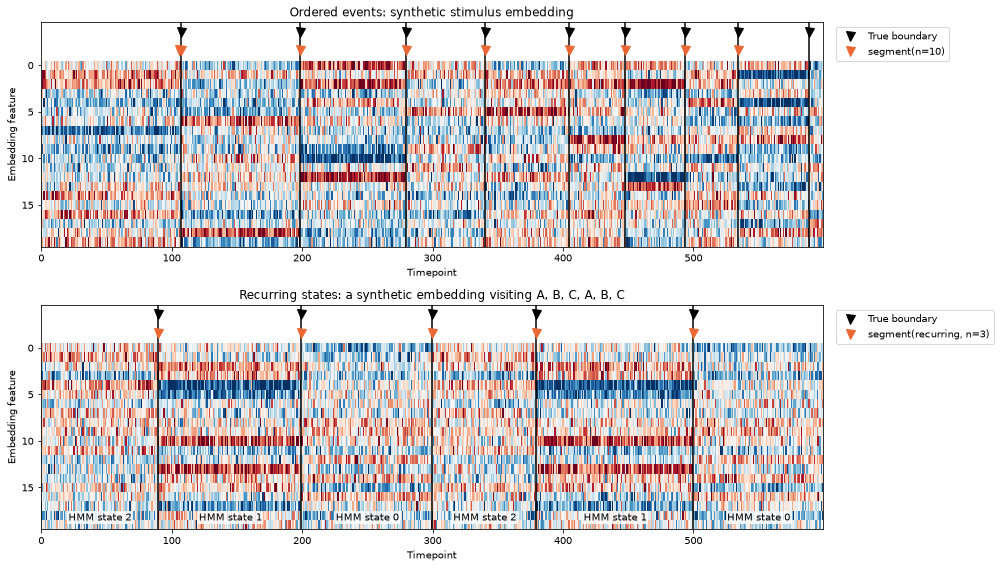

In [9]:
def show_embedding(ax, emb, true_b, found_b, found_label, title):
    """Embedding heatmap; true boundaries as black lines and triangles above the image,
    boundaries found by tc.segment as orange triangles in a second row."""
    ax.imshow(emb.T, aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3, interpolation='nearest',
              extent=(-0.5, emb.shape[0] - 0.5, E - 0.5, -0.5))
    for b in true_b[1:]:
        ax.axvline(b - 0.5, color='k', lw=1.5)
    ax.plot(np.asarray(true_b[1:]) - 0.5, np.full(len(true_b) - 1, -3.6), 'v', color='k', ms=9,
            clip_on=False, label='True boundary')
    ax.plot(np.asarray(found_b[1:]) - 0.5, np.full(len(found_b) - 1, -1.6), 'v', color=orange, ms=9,
            clip_on=False, label=found_label)
    ax.set_ylim(E - 0.5, -4.6)
    ax.set_yticks([0, 5, 10, 15])
    ax.set_title(title)
    ax.set_xlabel('Timepoint')
    ax.set_ylabel('Embedding feature')
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=10)


fig, axes = plt.subplots(2, 1, figsize=(14, 8))
show_embedding(axes[0], embedding, true_bounds, seg_n, 'segment(n=10)',
               'Ordered events: synthetic stimulus embedding')
show_embedding(axes[1], rec_embedding, np.r_[0, np.cumsum(lengths)[:-1]], rec_bounds,
               'segment(recurring, n=3)',
               'Recurring states: a synthetic embedding visiting A, B, C, A, B, C')
starts = list(rec_bounds) + [T]
for a, b in zip(starts[:-1], starts[1:]):
    axes[1].text((a + b) / 2, E - 1.2, f'HMM state {rec_states[a]}', ha='center', va='bottom',
                 fontsize=10, bbox=dict(fc='white', ec='none', alpha=0.85, pad=1.5))
fig.tight_layout()

### Using the events on brain data: recovery of the true correlations

The events found in the stimulus embedding are now passed to `timecorr` for the brain data (`cfun=tc.autofc`, within-subject correlations; Gaussian kernel, `var` 100). Four kernels are compared:

- **unrestricted**: no events;
- **true events**: the generator's boundaries;
- **segmented events**: `tc.segment(embedding, n=<true number of events>)`;
- **wrong events** (control): the same number of boundaries at random positions.

The score at each timepoint is the Pearson correlation between the estimated and the true off-diagonal correlations. It is averaged over all timepoints, and over the timepoints within 10 samples of a true boundary, for 8 datasets (seeds 0 to 7).

In [10]:
NEAR = 10
kernel = {'weights_function': tc.gaussian_weights, 'weights_params': {'var': 100}}


def recovery(brain, truth, events):
    """Per-timepoint r between estimated and true off-diagonal correlations."""
    est = tc.timecorr(brain, cfun=tc.autofc, events=events, **kernel)
    est = np.moveaxis(tc.vec2mat(est), 2, 0)[:, iu[0], iu[1]]
    est_c = est - est.mean(1, keepdims=True)
    tru_c = truth - truth.mean(1, keepdims=True)
    with np.errstate(invalid='ignore', divide='ignore'):
        # undefined (NaN) where a block of 1 or 2 timepoints has no estimate
        return (est_c * tru_c).sum(1) / np.sqrt((est_c ** 2).sum(1) * (tru_c ** 2).sum(1))


conditions = ['unrestricted', 'true events', 'segmented events', 'wrong events']
scores = {c: [] for c in conditions}
for seed in range(8):
    embedding_s, brain_s, truth_s, true_s, wrong_s = make_data(seed)
    segmented_s = tc.segment(embedding_s, n=len(true_s))
    near = np.zeros(T, bool)
    for b in true_s[1:]:
        near[max(0, b - NEAR):b + NEAR] = True
    with warnings.catch_warnings():
        # blocks of 1 or 2 timepoints (a short last event, or a 2-timepoint segmented
        # event) have undefined correlations; timecorr warns, and they are left out below
        warnings.filterwarnings('ignore', message='.*fewer than 3 non-zero kernel weights')
        for c, ev in zip(conditions, [None, true_s, segmented_s, wrong_s]):
            r = recovery(brain_s, truth_s, ev)
            if seed == 0:
                scores.setdefault(c + ' (seed 0)', r)
            scores[c].append([np.nanmean(r), np.nanmean(r[near])])

summary = {c: np.array(scores[c]) for c in conditions}
print(f'{"kernel":18s} {"overall":>16s} {"near boundaries":>18s}   (mean +- s.e. over 8 seeds)')
for c in conditions:
    m, se = summary[c].mean(0), summary[c].std(0, ddof=1) / np.sqrt(8)
    print(f'{c:18s} {m[0]:8.3f} +- {se[0]:.3f} {m[1]:10.3f} +- {se[1]:.3f}')
diff = summary['true events'] - summary['unrestricted']
print('\ntrue events minus unrestricted, paired: overall %.3f (s.d. %.3f), near %.3f (s.d. %.3f)'
      % (diff[:, 0].mean(), diff[:, 0].std(ddof=1), diff[:, 1].mean(), diff[:, 1].std(ddof=1)))
diff = summary['wrong events'] - summary['unrestricted']
print('wrong events minus unrestricted, paired: overall %.3f (s.d. %.3f), near %.3f (s.d. %.3f)'
      % (diff[:, 0].mean(), diff[:, 0].std(ddof=1), diff[:, 1].mean(), diff[:, 1].std(ddof=1)))

kernel                      overall    near boundaries   (mean +- s.e. over 8 seeds)
unrestricted          0.891 +- 0.004      0.779 +- 0.004
true events           0.919 +- 0.002      0.893 +- 0.003
segmented events      0.916 +- 0.002      0.883 +- 0.005
wrong events          0.878 +- 0.005      0.766 +- 0.005

true events minus unrestricted, paired: overall 0.028 (s.d. 0.006), near 0.114 (s.d. 0.013)
wrong events minus unrestricted, paired: overall -0.013 (s.d. 0.004), near -0.013 (s.d. 0.012)


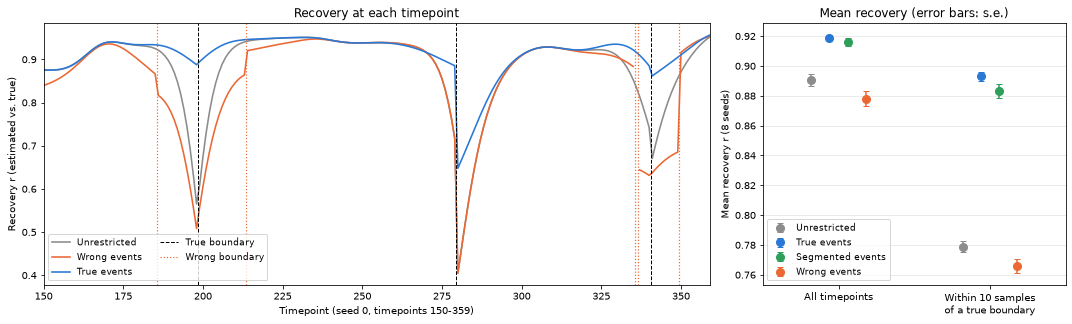

In [11]:
colors = dict(zip(conditions, [gray, blue, green, orange]))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={'width_ratios': [2.2, 1]})

ax = axes[0]
_, _, _, true0, wrong0 = make_data(0)
window = slice(150, 360)
tt = np.arange(T)[window]
for c in ['unrestricted', 'wrong events', 'true events']:
    ax.plot(tt, scores[c + ' (seed 0)'][window], color=colors[c], lw=1.6, label=c.capitalize())
for i, b in enumerate(true0[(true0 > tt[0]) & (true0 < tt[-1])]):
    ax.axvline(b - 0.5, color='k', ls='--', lw=1, label='True boundary' if i == 0 else None)
for i, b in enumerate(wrong0[(wrong0 > tt[0]) & (wrong0 < tt[-1])]):
    ax.axvline(b - 0.5, color=orange, ls=':', lw=1.2, label='Wrong boundary' if i == 0 else None)
ax.set_xlim(tt[0], tt[-1])
ax.set_xlabel('Timepoint (seed 0, timepoints 150-359)')
ax.set_ylabel('Recovery r (estimated vs. true)')
ax.set_title('Recovery at each timepoint')
ax.legend(loc='lower left', fontsize=9, ncol=2)

ax = axes[1]
x = np.arange(2)
for i, c in enumerate(conditions):
    m = summary[c].mean(0)
    se = summary[c].std(0, ddof=1) / np.sqrt(8)
    ax.errorbar(x + (i - 1.5) * 0.12, m, yerr=se, fmt='o', ms=8, color=colors[c], capsize=3,
                label=c.capitalize())
ax.set_xticks(x, ['All timepoints', f'Within {NEAR} samples\nof a true boundary'])
ax.set_xlim(-0.5, 1.5)
ax.set_ylabel('Mean recovery r (8 seeds)')
ax.set_title('Mean recovery (error bars: s.e.)')
ax.grid(axis='y', color='0.9')
ax.legend(loc='lower left', fontsize=9)
fig.tight_layout()

On these 8 datasets, at order 1, the kernel restricted to the true events recovered the true correlations better than the unrestricted kernel: mean r 0.919 versus 0.891 over all timepoints, and 0.893 versus 0.779 within 10 samples of a true boundary (paired differences 0.028, s.d. 0.006, and 0.114, s.d. 0.013). The events segmented from the stimulus embedding gave 0.916 and 0.883. The wrong boundaries, which cut the kernel just as often, did not help: 0.878 and 0.766, slightly below the unrestricted kernel.

The left panel shows where the difference comes from. Near a true boundary the unrestricted kernel mixes timepoints from two events, which have different correlations, and its recovery dips; the kernel restricted to the true events dips less. Wrong boundaries cut the kernel where the correlations do not change, so they shorten the window there (and add dips of their own), and they leave the dips at the true boundaries in place.

These numbers are for this generator, in which the correlations change abruptly at the event boundaries and the stimulus embedding has clear events.

## 4. Per-subject events

`events` may also be a list with one entry per subject. Each entry is `None` (no restriction), a boundary set, or a features array to segment. `tc.segment` accepts a list of timeseries and returns a list of boundary sets, one per timeseries, so each subject's own stimulus or behavioral timeseries can be segmented separately. Subjects whose boundaries are identical share one kernel.

Below, three subjects see the same sequence of events, but each subject's events start at a different time. Their embeddings are segmented separately and passed as per-subject events. With `cfun=tc.autofc`, each subject's output equals a single-subject call with that subject's boundaries.

In [12]:
rng = np.random.default_rng(2)
T3, n_events = 300, 4
subject_bounds, subject_embeddings, subject_brain = [], [], []
for shift in (0, 10, 20):
    b = np.array([0, 70, 150, 220]) + np.array([0, shift, shift, shift])
    labels = np.repeat(np.arange(n_events), np.diff(np.r_[b, T3]))
    subject_embeddings.append(rng.standard_normal((n_events, E))[labels] + rng.standard_normal((T3, E)))
    subject_brain.append(rng.standard_normal((T3, K)))
    subject_bounds.append(b)

segmented = tc.segment(subject_embeddings, n=n_events)
for s, (b, seg) in enumerate(zip(subject_bounds, segmented)):
    print(f'subject {s}: true {b.tolist()}, segmented {seg.tolist()}')

per_subject = tc.timecorr(subject_brain, cfun=tc.autofc, events=segmented, **kernel)
alone = tc.timecorr(subject_brain[1], cfun=tc.autofc, events=segmented[1], **kernel)
print('subject 1 equals a single-subject call with its own events:', np.allclose(per_subject[1], alone))

subject 0: true [0, 70, 150, 220], segmented [0, 70, 150, 220]
subject 1: true [0, 80, 160, 230], segmented [0, 80, 160, 230]
subject 2: true [0, 90, 170, 240], segmented [0, 90, 170, 240]


subject 1 equals a single-subject call with its own events: True


With cross-subject correlation functions (`tc.isfc`, `tc.wisfc`), subject s's output at timepoint `t` uses subject s's restricted kernel row for both subject s's data and the reference it is correlated with (the average of the other subjects for `isfc`, the weighted average for `wisfc`); the reference is not restricted by the other subjects' events. From the `timecorr` documentation:

> With per-subject events and a cross-subject correlation function (`isfc`, `wisfc`), the timepoints that enter subject s's correlations at time t are those in subject s's current block, for both subject s's data and the other subjects' data. If the subjects' events occur at different times, the other subjects' data inside that window may come from different events. Cross-subject correlations assume that all subjects experience the same external stimulus at the same times; per-subject events that are not aligned across subjects are better suited to within-subject correlations (`cfun=autofc`).

In [13]:
isfc_per_subject = tc.timecorr(subject_brain, cfun=tc.isfc, events=segmented, **kernel)
print(len(isfc_per_subject), 'subjects, each', isfc_per_subject[0].shape)

3 subjects, each (300, 55)


## 5. Different events at each order in `tc.features`

In `tc.features`, `events` may be a dict that maps orders to event specifications; orders missing from the dict are unrestricted, and a value that is not a dict applies to every order. At order `k` only the **analysis** kernel is restricted (it gives `X_k`); the delta path, which computes the co-fluctuations passed to the next order, is never restricted. `events_params` may likewise be a dict keyed by order, for orders whose events are features to segment.

Below, order 1 is restricted to the events segmented from the stimulus embedding of section 3 (segmentation runs inside `tc.features`, with the parameters given for order 1), and order 2 to a hand-picked boundary set.

In [14]:
with warnings.catch_warnings():
    # the segmented events include a 2-timepoint event (section 3), whose correlations
    # are undefined and set to 0; timecorr warns about it on every call
    warnings.filterwarnings('ignore', message='.*fewer than 3 non-zero kernel weights')
    X, D = tc.features(brain, order=2, cfun=tc.autofc, rfun=None, return_delta=True,
                       events={1: embedding, 2: [0, 300]},
                       events_params={1: {'n': len(true_bounds)}}, **kernel)
    order1 = tc.timecorr(brain, cfun=tc.autofc, events=seg_n, **kernel)
order2 = tc.timecorr(D[1], cfun=tc.autofc, events=[0, 300], **kernel)
print('shapes:', [x.shape for x in X])

# order 1 equals timecorr with the segmented events; order 2 equals timecorr on the
# order-1 co-fluctuations D[1] with the order-2 events
print('X[1] matches timecorr(brain, events=segment(embedding, n=10)):', np.allclose(X[1], order1))
print('X[2] matches timecorr(D[1], events=[0, 300]):', np.allclose(X[2], order2))

shapes: [(600, 10), (600, 55), (600, 1540)]
X[1] matches timecorr(brain, events=segment(embedding, n=10)): True
X[2] matches timecorr(D[1], events=[0, 300]): True


In our synthetic tests, restricting the kernel to the true events improved recovery at order 1 (section 3). At order 2 the default pipeline recovered little of the simulated structure with or without events, so these tests do not show whether events help there.

## Summary

- `events=` confines `timecorr`'s kernel to blocks of consecutive timepoints: timepoints in other blocks get zero weight.
- Boundaries can be passed directly, or found with `tc.segment` in a separate timeseries: `kind='ordered'` (each event once, in order; `n` given or chosen automatically) or `kind='recurring'` (`n` states that may be revisited; each visit is its own block).
- On the synthetic data of section 3, at order 1, restricting the kernel to the true events (or to events segmented from the stimulus embedding) recovered the true correlations better than the unrestricted kernel, most of all near boundaries; wrong boundaries did not.
- Events may differ per subject (with the limitation above for `isfc` and `wisfc`) and, in `tc.features`, per order.

Reference: Heusser, A. C., Fitzpatrick, P. C. & Manning, J. R. Geometric models reveal behavioural and neural signatures of transforming experiences into memories. *Nature Human Behaviour* 5, 905-919 (2021). [doi:10.1038/s41562-021-01051-6](https://doi.org/10.1038/s41562-021-01051-6)